# NN Pruning Experiment 4 — Natural parsimony test (clean)

**Goal**: prove natural parsimony emerges from CMA-ES dimensionality pressure, NOT from biased mutations.

**Setup**:
- Mutation operator **quantum-style** (40% SWAP / 20% REMOVE / 40% ADD, fixed weights, no `f_target` knowledge)
- Mutation has **net drift +0.2 bits per step** (ADD biased over REMOVE)
- Initialize at `density = F_TARGET = 0.05`
- ALPHA=0 (no score penalty)
- ALPHA=500 secondary run (sanity check that unbiased mutation still works with score penalty)

**Hypothesis**: density stays around 0.05 across 40 epochs. If true → selection pressure from CMA-ES inner loop in higher dim is strong enough to compensate the +0.2 drift → **natural parsimony confirmed**.

All other hyperparameters byte-identical to exp3 (and quantum exp4).

In [1]:
import json, os, warnings, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import cma
from joblib import Parallel, delayed
from sklearn.datasets import load_wine, load_iris, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pickle

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [ ]:
DATASETS  = ["iris", "wine", "cancer"]
HIDDEN    = [64, 32]
F_TARGET  = 0.05
DEVICE    = "cpu"
SEEDS     = [0, 1, 2, 3, 4]

POP_SIZE      = 100
N_EPOCH_MULTI = 40
ELITISM       = 10
RESEED        = 20
INNER_BUDGET  = 150
INNER_SIGMA0  = 0.3

MIN_DENSITY   = 0.005    

ALPHA_NATURAL = 0.0
ALPHA_MAIN    = 500.0

RESULTS_FILE = "nnpruning4_results.pkl"

X_tr = y_tr = X_te = y_te = None
IN_DIM = OUT_DIM = None
DIMS = None

In [3]:
def load_dataset(name):
    if name == "iris":
        d = load_iris()
    elif name == "wine":
        d = load_wine()
    elif name == "cancer":
        d = load_breast_cancer()
    else:
        raise ValueError(name)
    X, y = d.data, d.target
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    sc = StandardScaler().fit(X_tr)
    X_tr = torch.tensor(sc.transform(X_tr), dtype=torch.float32)
    X_te = torch.tensor(sc.transform(X_te), dtype=torch.float32)
    y_tr = torch.tensor(y_tr, dtype=torch.long)
    y_te = torch.tensor(y_te, dtype=torch.long)
    return X_tr, y_tr, X_te, y_te, int(X_tr.shape[1]), int(len(set(d.target.tolist())))

def activate_dataset(name):
    global X_tr, y_tr, X_te, y_te, IN_DIM, OUT_DIM, DIMS
    X_tr, y_tr, X_te, y_te, IN_DIM, OUT_DIM = load_dataset(name)
    DIMS = [IN_DIM] + HIDDEN + [OUT_DIM]
    print(f"{name}: in={IN_DIM}, out={OUT_DIM}, train={len(X_tr)}, test={len(X_te)}, dims={DIMS}")

In [4]:
class MaskedMLP(nn.Module):
    def __init__(self, dims=None):
        super().__init__()
        if dims is None:
            dims = DIMS
        self.dims = list(dims)
        self.layers = nn.ModuleList([nn.Linear(self.dims[i], self.dims[i+1]) for i in range(len(self.dims)-1)])
        self.masks = nn.ParameterList([
            nn.Parameter(torch.ones_like(l.weight), requires_grad=False)
            for l in self.layers
        ])

    def forward(self, x):
        for i, l in enumerate(self.layers):
            w = l.weight * self.masks[i]
            x = F.linear(x, w, l.bias)
            if i < len(self.layers) - 1:
                x = F.relu(x)
        return x

    def density(self):
        total = sum(m.numel() for m in self.masks)
        active = sum(float(m.sum().item()) for m in self.masks)
        return active / total

    def clone_arch(self):
        new = MaskedMLP(self.dims)
        for i, l in enumerate(self.layers):
            new.layers[i].weight.data.copy_(l.weight.data)
            new.layers[i].bias.data.copy_(l.bias.data)
            new.masks[i].data.copy_(self.masks[i].data)
        return new

## Quantum-style mutation (40% SWAP / 20% REMOVE / 40% ADD)

**No f_target awareness.** Direct port of `random_modif` from QKD_experiment_4.ipynb:
- 40% SWAP: pick one active bit, flip to 0; pick one inactive bit, flip to 1 → **count unchanged**
- 20% REMOVE: pick one active bit, flip to 0 → **count -1**
- 40% ADD: pick one inactive bit, flip to 1 → **count +1**

Floor at `MIN_DENSITY` to prevent trivially empty models (analog to `n > 2` in quantum).

In [5]:
def _flip_one_active(model):
    """Flip one active bit to 0. Returns (li, idx) of flipped bit, or None if no active."""
    li = np.random.randint(len(model.masks))
    m = model.masks[li]
    active = torch.where(m.data.flatten() > 0.5)[0]
    if len(active) == 0:
        return None
    flat = int(active[np.random.randint(len(active))].item())
    idx = np.unravel_index(flat, m.shape)
    m.data[idx] = 0.0
    return (li, idx)

def _flip_one_inactive(model):
    """Flip one inactive bit to 1. Returns (li, idx) of flipped bit, or None."""
    li = np.random.randint(len(model.masks))
    m = model.masks[li]
    inactive = torch.where(m.data.flatten() < 0.5)[0]
    if len(inactive) == 0:
        return None
    flat = int(inactive[np.random.randint(len(inactive))].item())
    idx = np.unravel_index(flat, m.shape)
    m.data[idx] = 1.0
    return (li, idx)

def random_modif_quantum(model, n_flips=None, min_density=MIN_DENSITY):
    """Quantum-style mutation: SWAP / REMOVE / ADD with fixed 40/20/40 weights.
    No f_target awareness. Direct port of QKD_experiment_4 random_modif."""
    model = model.clone_arch()
    total = sum(m.numel() for m in model.masks)
    if n_flips is None:
        n_flips = max(1, int(0.02 * total))
    min_active = max(1, int(min_density * total))

    for _ in range(n_flips):
        active_count = sum(int(m.data.sum().item()) for m in model.masks)
        a = np.random.random()

        if a < 0.4 and active_count > 0 and active_count < total:
            # SWAP
            removed = _flip_one_active(model)
            if removed is None:
                continue
            added = _flip_one_inactive(model)
            if added is None:
                # revert if no inactive available
                model.masks[removed[0]].data[removed[1]] = 1.0
        elif a < 0.6 and active_count > min_active:
            # REMOVE
            _flip_one_active(model)
        else:
            # ADD
            if active_count < total:
                _flip_one_inactive(model)
    return model

def random_ini(density=0.05, dims=None):
    if dims is None:
        dims = DIMS
    model = MaskedMLP(dims)
    for i in range(len(model.masks)):
        model.masks[i].data = (torch.rand_like(model.masks[i]) < density).float()
    return model

## CMA-ES inner loop (identical to exp3)

In [6]:
def _collect_active_params(model):
    init_vals = []
    layout = []
    for li, l in enumerate(model.layers):
        mask = model.masks[li].data
        rows, cols = torch.where(mask > 0.5)
        for r, c in zip(rows.tolist(), cols.tolist()):
            init_vals.append(float(l.weight.data[r, c].item()))
            layout.append(("w", li, r, c))
    for li, l in enumerate(model.layers):
        for bi in range(l.bias.numel()):
            init_vals.append(float(l.bias.data[bi].item()))
            layout.append(("b", li, bi))
    return np.array(init_vals, dtype=np.float64), layout

def _apply_vec(model, x, layout):
    with torch.no_grad():
        for k, item in enumerate(layout):
            if item[0] == "w":
                _, li, r, c = item
                model.layers[li].weight.data[r, c] = float(x[k])
            else:
                _, li, bi = item
                model.layers[li].bias.data[bi] = float(x[k])
        for li, l in enumerate(model.layers):
            l.weight.data.mul_(model.masks[li])

def train_inner_cmaes(model, X, y, budget=INNER_BUDGET, sigma0=INNER_SIGMA0, seed=None):
    init_vec, layout = _collect_active_params(model)
    n = len(init_vec)
    if n == 0:
        return model

    def loss_fn(x):
        _apply_vec(model, x, layout)
        with torch.no_grad():
            out = model(X)
            l = F.cross_entropy(out, y).item()
        return float(l) if not np.isnan(l) else 1e6

    opts = {"maxfevals": budget, "verbose": -9, "seed": int(seed) if seed is not None else 0,
            "tolx": 1e-8, "tolfun": 1e-8}
    es = cma.CMAEvolutionStrategy(init_vec.tolist(), sigma0, opts)
    es.optimize(loss_fn)
    best_x = es.result.xbest if es.result.xbest is not None else init_vec
    _apply_vec(model, best_x, layout)
    return model

In [7]:
class EvalCounter:
    def __init__(self): self.n = 0
    def reset(self): self.n = 0

EVAL = EvalCounter()

def eval_accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        pred = model(X).argmax(dim=1)
        return float((pred == y).float().mean().item())

def score(model, f_target, alpha, seed=None):
    EVAL.n += 1
    model = train_inner_cmaes(model, X_tr, y_tr, seed=seed)
    acc_tr = eval_accuracy(model, X_tr, y_tr)
    acc_te = eval_accuracy(model, X_te, y_te)
    density = model.density()
    s = acc_te - alpha * (density - f_target) ** 2
    if np.isnan(s):
        s = -1e6
    return s, acc_tr, acc_te, density, model

## Outer loop using quantum-style mutation

In [ ]:
def run_inner_eval(model, f_target, alpha, seed=None):
    warnings.filterwarnings("ignore")
    try:
        s, acc_tr, acc_te, density, trained = score(model, f_target, alpha, seed=seed)
        return s, acc_tr, acc_te, density, trained
    except Exception as e:
        print(f"eval failed: {e}")
        return -1e6, 0.0, 0.0, 1.0, model

def train_evolutive(init_pop, n_epoch, f_target, alpha,
                    n_jobs=-1, elitism=ELITISM, reseed=RESEED, verbose=False,
                    min_epoch=20, patience=10, tol=1e-4, base_seed=0,
                    init_density=F_TARGET):
    history = {k: {"acc_tr": [], "acc_te": [], "density": [], "loss": []}
               for k in ("best", "second", "third", "mid")}
    avg_density = []
    pop_size = len(init_pop)
    circuit_list = init_pop
    for epoch in range(n_epoch):
        evaluated = Parallel(n_jobs=n_jobs)(
            delayed(run_inner_eval)(m, f_target, alpha, seed=base_seed * 10000 + epoch * pop_size + i)
            for i, m in enumerate(circuit_list))
        scored = []
        for i, (s, atr, ate, d, trained) in enumerate(evaluated):
            scored.append((s, i, atr, ate, d))
            circuit_list[i] = trained
        scored.sort(reverse=True)
        for key, rank in (("best", 0), ("second", 1), ("third", 2),
                          ("mid", len(scored) // 2)):
            history[key]["acc_tr"].append(scored[rank][2])
            history[key]["acc_te"].append(scored[rank][3])
            history[key]["density"].append(scored[rank][4])
            history[key]["loss"].append(-scored[rank][0])

        max_s = scored[0][0]
        lo, hi = elitism, pop_size - reseed
        weights = np.array([max_s - t[0] + 1e-6 for t in scored[lo:hi]])
        probs = weights / weights.sum()
        picks = set(np.random.choice(range(lo, hi), size=reseed,
                                     replace=False, p=probs).tolist())

        for i in range(1, reseed + 1):
            circuit_list[scored[-i][1]] = random_ini(density=init_density)

        parent_ranks = [k // 2 for k in range(reseed)]
        assert parent_ranks[-1] < elitism

        for pr, i in zip(parent_ranks, sorted(picks)):
            parent = circuit_list[scored[pr][1]]
            circuit_list[scored[i][1]] = random_modif_quantum(parent)
        for i in range(lo, hi):
            if i not in picks:
                circuit_list[scored[i][1]] = random_modif_quantum(circuit_list[scored[i][1]])

        avg_density.append(float(np.mean([m.density() for m in circuit_list])))
        if verbose:
            print(f"  epoch {epoch:3d}  acc_te={scored[0][3]:.4f}  "
                  f"density={scored[0][4]:.3f}  avg_d={avg_density[-1]:.3f}")

        if epoch + 1 >= min_epoch:
            recent = history["best"]["loss"][-patience:]
            if len(recent) == patience and (max(recent) - min(recent)) < tol:
                if verbose:
                    print(f"  early stop at epoch {epoch}")
                break

    best_model = circuit_list[scored[0][1]]
    return best_model, circuit_list, avg_density, history

## Sanity test on Iris (5 epochs, ALPHA=0)

Watch the density: with quantum-style mutation and ALPHA=0, does it stay near 0.05 or drift up?

In [9]:
activate_dataset("iris")
set_all_seeds(0)
EVAL.reset()
init_pop = [random_ini(density=F_TARGET) for _ in range(POP_SIZE)]
import time
t0 = time.time()
best, pop, avg_d, hist = train_evolutive(
    init_pop, n_epoch=5, f_target=F_TARGET, alpha=ALPHA_NATURAL,
    verbose=True, base_seed=0, init_density=F_TARGET)
print(f"5 epochs took {time.time()-t0:.1f}s")
print(f"final best: acc_te={hist['best']['acc_te'][-1]:.4f}, density={hist['best']['density'][-1]:.3f}")
print(f"avg density trajectory: {[f'{d:.3f}' for d in avg_d]}")

iris: in=4, out=3, train=105, test=45, dims=[4, 64, 32, 3]
  epoch   0  acc_te=0.6667  density=0.052  avg_d=0.053
  epoch   1  acc_te=0.9333  density=0.056  avg_d=0.055
  epoch   2  acc_te=0.9556  density=0.060  avg_d=0.057
  epoch   3  acc_te=0.9556  density=0.060  avg_d=0.060
  epoch   4  acc_te=0.9556  density=0.054  avg_d=0.062
5 epochs took 23.4s
final best: acc_te=0.9556, density=0.054
avg density trajectory: ['0.053', '0.055', '0.057', '0.060', '0.062']


## Full runs

Two configurations, same quantum-style mutation:
- ALPHA=0 (main test of natural parsimony)
- ALPHA=500 (sanity check that score penalty still works without mutation bias)

In [10]:
def run_seed(name, seed, alpha, init_density=F_TARGET):
    activate_dataset(name)
    set_all_seeds(seed)
    EVAL.reset()
    init_pop = [random_ini(density=init_density) for _ in range(POP_SIZE)]
    best, pop, avg_d, hist = train_evolutive(
        init_pop, n_epoch=N_EPOCH_MULTI, f_target=F_TARGET, alpha=alpha,
        verbose=False, base_seed=seed, init_density=init_density)
    return best, pop, avg_d, hist, EVAL.n

def run_all(alpha, label, init_density=F_TARGET):
    print(f"\n{'='*60}\nRUN: {label} (ALPHA={alpha}, init_d={init_density})\n{'='*60}")
    out = {}
    for ds in DATASETS:
        out[ds] = {"best": [], "pop": [], "avg_d": [], "hist": [], "evals": []}
        for s in SEEDS:
            print(f"  [{ds}] seed={s} ...")
            import time; t0 = time.time()
            b, p, a, h, e = run_seed(ds, s, alpha, init_density=init_density)
            print(f"    done in {time.time()-t0:.0f}s, acc_te={h['best']['acc_te'][-1]:.4f}, "
                  f"density={h['best']['density'][-1]:.3f}, avg_d_final={a[-1]:.3f}")
            out[ds]["best"].append(b)
            out[ds]["pop"].append(p)
            out[ds]["avg_d"].append(a)
            out[ds]["hist"].append(h)
            out[ds]["evals"].append(e)
    return out

In [11]:
results = {}
results["alpha_natural_qmut"] = run_all(ALPHA_NATURAL, "alpha=0 + quantum-style mutation (NATURAL PARSIMONY TEST)")
with open(RESULTS_FILE, "wb") as f:
    pickle.dump(results, f)
print(f"\nsaved {RESULTS_FILE} (natural test only)")

results["alpha_main_qmut"] = run_all(ALPHA_MAIN, "alpha=500 + quantum-style mutation (sanity check)")
with open(RESULTS_FILE, "wb") as f:
    pickle.dump(results, f)
print(f"\nsaved {RESULTS_FILE} (final)")


RUN: alpha=0 + quantum-style mutation (NATURAL PARSIMONY TEST) (ALPHA=0.0, init_d=0.05)
  [iris] seed=0 ...
iris: in=4, out=3, train=105, test=45, dims=[4, 64, 32, 3]
    done in 195s, acc_te=1.0000, density=0.172, avg_d_final=0.156
  [iris] seed=1 ...
iris: in=4, out=3, train=105, test=45, dims=[4, 64, 32, 3]
    done in 185s, acc_te=1.0000, density=0.181, avg_d_final=0.152
  [iris] seed=2 ...
iris: in=4, out=3, train=105, test=45, dims=[4, 64, 32, 3]
    done in 184s, acc_te=1.0000, density=0.180, avg_d_final=0.148
  [iris] seed=3 ...
iris: in=4, out=3, train=105, test=45, dims=[4, 64, 32, 3]
    done in 74s, acc_te=0.9778, density=0.105, avg_d_final=0.102
  [iris] seed=4 ...
iris: in=4, out=3, train=105, test=45, dims=[4, 64, 32, 3]
    done in 101s, acc_te=1.0000, density=0.124, avg_d_final=0.118
  [wine] seed=0 ...
wine: in=13, out=3, train=124, test=54, dims=[13, 64, 32, 3]
    done in 128s, acc_te=1.0000, density=0.125, avg_d_final=0.118
  [wine] seed=1 ...
wine: in=13, out=3, 

    done in 264s, acc_te=0.9942, density=0.169, avg_d_final=0.143
  [cancer] seed=3 ...
cancer: in=30, out=2, train=398, test=171, dims=[30, 64, 32, 2]
    done in 244s, acc_te=0.9942, density=0.148, avg_d_final=0.125
  [cancer] seed=4 ...
cancer: in=30, out=2, train=398, test=171, dims=[30, 64, 32, 2]
    done in 248s, acc_te=0.9883, density=0.159, avg_d_final=0.130

saved nnpruning4_results.pkl (natural test only)

RUN: alpha=500 + quantum-style mutation (sanity check) (ALPHA=500.0, init_d=0.05)
  [iris] seed=0 ...
iris: in=4, out=3, train=105, test=45, dims=[4, 64, 32, 3]
    done in 127s, acc_te=0.9556, density=0.050, avg_d_final=0.058
  [iris] seed=1 ...
iris: in=4, out=3, train=105, test=45, dims=[4, 64, 32, 3]
    done in 128s, acc_te=0.9778, density=0.056, avg_d_final=0.060
  [iris] seed=2 ...
iris: in=4, out=3, train=105, test=45, dims=[4, 64, 32, 3]
    done in 129s, acc_te=0.9556, density=0.055, avg_d_final=0.060
  [iris] seed=3 ...
iris: in=4, out=3, train=105, test=45, dim

    done in 151s, acc_te=0.9630, density=0.051, avg_d_final=0.061
  [wine] seed=2 ...
wine: in=13, out=3, train=124, test=54, dims=[13, 64, 32, 3]
    done in 150s, acc_te=1.0000, density=0.052, avg_d_final=0.061
  [wine] seed=3 ...
wine: in=13, out=3, train=124, test=54, dims=[13, 64, 32, 3]
    done in 149s, acc_te=0.9815, density=0.052, avg_d_final=0.061
  [wine] seed=4 ...
wine: in=13, out=3, train=124, test=54, dims=[13, 64, 32, 3]
    done in 147s, acc_te=1.0000, density=0.050, avg_d_final=0.059
  [cancer] seed=0 ...
cancer: in=30, out=2, train=398, test=171, dims=[30, 64, 32, 2]
    done in 184s, acc_te=0.9766, density=0.051, avg_d_final=0.058
  [cancer] seed=1 ...
cancer: in=30, out=2, train=398, test=171, dims=[30, 64, 32, 2]
    done in 185s, acc_te=0.9649, density=0.053, avg_d_final=0.057
  [cancer] seed=2 ...
cancer: in=30, out=2, train=398, test=171, dims=[30, 64, 32, 2]
    done in 186s, acc_te=0.9766, density=0.050, avg_d_final=0.057
  [cancer] seed=3 ...
cancer: in=30, 

## Aggregation

In [12]:
def aggregate(results, label):
    rows = []
    for ds in DATASETS:
        h_list = results[label][ds]["hist"]
        avg_d_list = results[label][ds]["avg_d"]
        acc        = np.array([h["best"]["acc_te"][-1] for h in h_list])
        dens_best  = np.array([h["best"]["density"][-1] for h in h_list])
        dens_avg   = np.array([a[-1] for a in avg_d_list])
        rows.append({
            "label": label,
            "dataset": ds,
            "acc_te":      f"{acc.mean():.3f} ± {acc.std():.3f}",
            "density_best": f"{dens_best.mean():.3f} ± {dens_best.std():.3f}",
            "density_avg_pop": f"{dens_avg.mean():.3f} ± {dens_avg.std():.3f}",
        })
    return pd.DataFrame(rows)

for k in results:
    print(aggregate(results, k))
    print()

                label dataset         acc_te   density_best density_avg_pop
0  alpha_natural_qmut    iris  0.996 ± 0.009  0.153 ± 0.032   0.135 ± 0.021
1  alpha_natural_qmut    wine  1.000 ± 0.000  0.120 ± 0.010   0.111 ± 0.009
2  alpha_natural_qmut  cancer  0.991 ± 0.003  0.156 ± 0.010   0.132 ± 0.006

             label dataset         acc_te   density_best density_avg_pop
0  alpha_main_qmut    iris  0.951 ± 0.017  0.052 ± 0.002   0.059 ± 0.001
1  alpha_main_qmut    wine  0.989 ± 0.015  0.051 ± 0.001   0.060 ± 0.001
2  alpha_main_qmut  cancer  0.970 ± 0.006  0.052 ± 0.002   0.058 ± 0.001



## Plots: density trajectory across epochs

**Key plot**: average population density vs epoch under ALPHA=0 with quantum-style mutation.
If density stays flat near 0.05 → natural parsimony confirmed.
If density drifts up → parsimony was an artefact of the biased mutator.

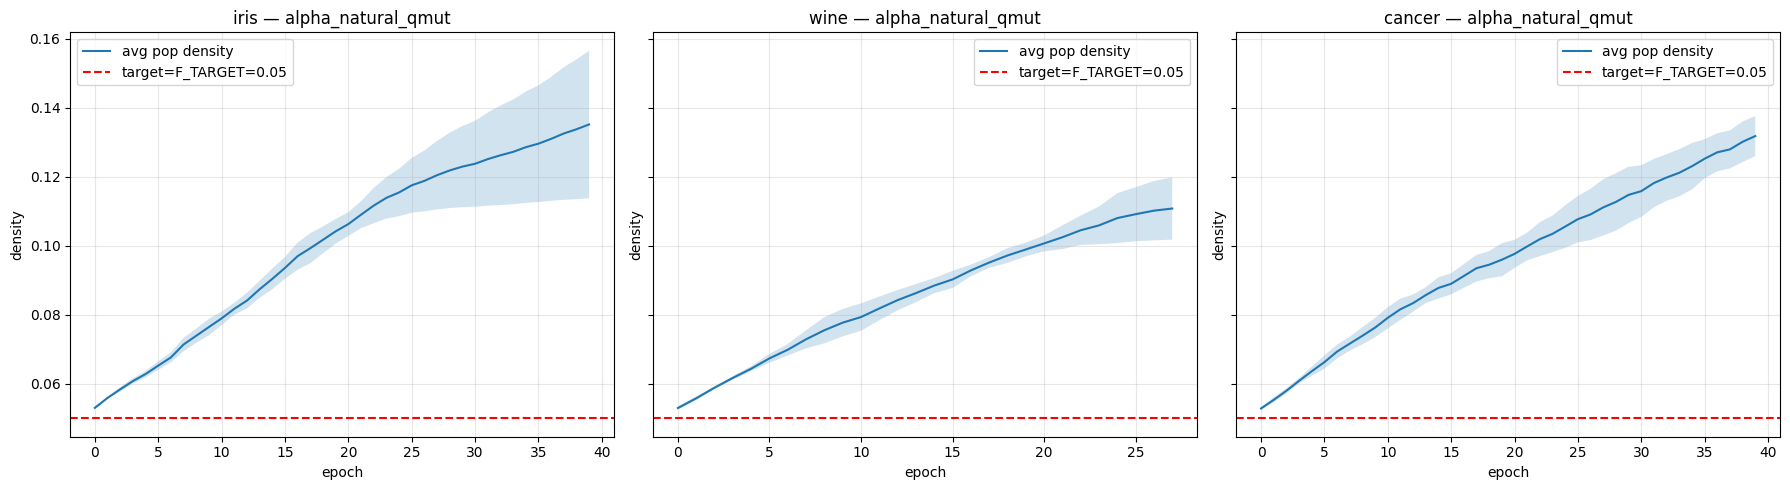

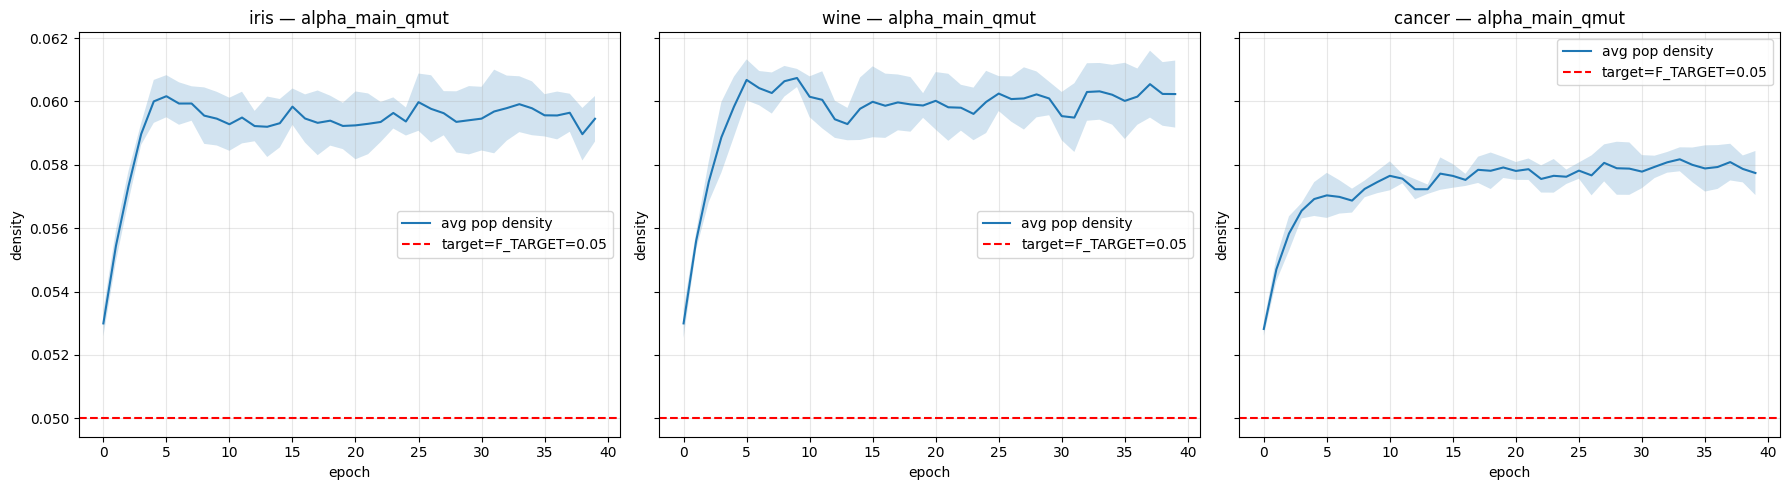

In [13]:
def _pad_right(arr, target_len):
    if len(arr) >= target_len:
        return arr[:target_len]
    return list(arr) + [arr[-1]] * (target_len - len(arr))

def plot_density_trajectories(results, label):
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(6*len(DATASETS), 5), sharey=True)
    if len(DATASETS) == 1:
        axes = [axes]
    for ax, ds in zip(axes, DATASETS):
        avg_d_list = results[label][ds]["avg_d"]
        max_len = max(len(a) for a in avg_d_list)
        arr = np.array([_pad_right(a, max_len) for a in avg_d_list])
        eps = np.arange(max_len)
        ax.plot(eps, arr.mean(axis=0), label="avg pop density")
        ax.fill_between(eps, arr.mean(0)-arr.std(0), arr.mean(0)+arr.std(0), alpha=0.2)
        ax.axhline(F_TARGET, color='red', linestyle='--', label=f'target=F_TARGET={F_TARGET}')
        ax.set_xlabel("epoch"); ax.set_ylabel("density")
        ax.set_title(f"{ds} — {label}")
        ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

for k in results:
    plot_density_trajectories(results, k)

## Comparison: exp3 (biased mutation) vs exp4 (unbiased quantum-style mutation)

In [14]:
try:
    with open("nnpruning3_results.pkl", "rb") as f:
        exp3 = pickle.load(f)
    print("exp3 results loaded for comparison")
    print("\n--- exp3 (biased mutation) ---")
    if "alpha_natural" in exp3:
        rows = []
        for ds in DATASETS:
            h_list = exp3["alpha_natural"][ds]["hist"]
            acc  = np.array([h["best"]["acc_te"][-1] for h in h_list])
            dens = np.array([h["best"]["density"][-1] for h in h_list])
            rows.append({"dataset": ds, "acc_te": f"{acc.mean():.3f}", "density": f"{dens.mean():.3f}"})
        print(pd.DataFrame(rows))
    print("\n--- exp4 (quantum-style mutation, alpha=0) ---")
    if "alpha_natural_qmut" in results:
        print(aggregate(results, "alpha_natural_qmut"))
except FileNotFoundError:
    print("nnpruning3_results.pkl not found, skip comparison")

exp3 results loaded for comparison

--- exp3 (biased mutation) ---
  dataset acc_te density
0    iris  0.978   0.057
1    wine  1.000   0.055
2  cancer  0.979   0.052

--- exp4 (quantum-style mutation, alpha=0) ---
                label dataset         acc_te   density_best density_avg_pop
0  alpha_natural_qmut    iris  0.996 ± 0.009  0.153 ± 0.032   0.135 ± 0.021
1  alpha_natural_qmut    wine  1.000 ± 0.000  0.120 ± 0.010   0.111 ± 0.009
2  alpha_natural_qmut  cancer  0.991 ± 0.003  0.156 ± 0.010   0.132 ± 0.006
